In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv("/content/AB_NYC_2019.csv")

print(df.head())

     id                                              name  host_id  \
0  2539                Clean & quiet apt home by the park     2787   
1  2595                             Skylit Midtown Castle     2845   
2  3647               THE VILLAGE OF HARLEM....NEW YORK !     4632   
3  3831                   Cozy Entire Floor of Brownstone     4869   
4  5022  Entire Apt: Spacious Studio/Loft by central park     7192   

     host_name neighbourhood_group neighbourhood  latitude  longitude  \
0         John            Brooklyn    Kensington  40.64749  -73.97237   
1     Jennifer           Manhattan       Midtown  40.75362  -73.98377   
2    Elisabeth           Manhattan        Harlem  40.80902  -73.94190   
3  LisaRoxanne            Brooklyn  Clinton Hill  40.68514  -73.95976   
4        Laura           Manhattan   East Harlem  40.79851  -73.94399   

         room_type  price  minimum_nights  number_of_reviews last_review  \
0     Private room    149               1                  9  20

In [2]:
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.describe())

# Missing values
print(df.isnull().sum())

# Missing value percentages
print((df.isnull().sum() / len(df)) * 100)

(48895, 16)
Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtyp

In [3]:
# Remove unnecessary columns
df = df.drop(
    ["id", "name", "host_id", "host_name",
     "last_review", "neighbourhood"],
    axis=1
)

# Handle missing values
df.loc[df["number_of_reviews"] == 0,
       "reviews_per_month"] = 0

df["reviews_per_month"] = df["reviews_per_month"].fillna(
    df["reviews_per_month"].median()
)

print(df.isnull().sum())

neighbourhood_group               0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64


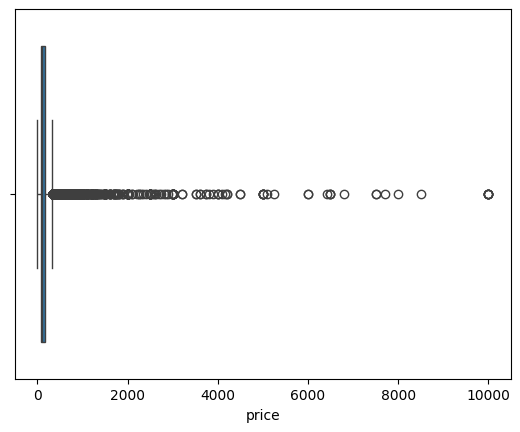

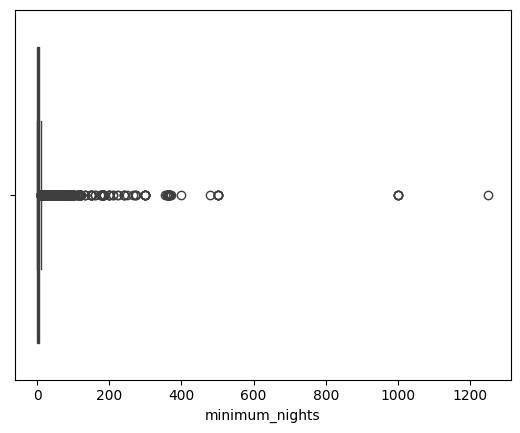

(45748, 10)


In [4]:
# Plot boxplots
sns.boxplot(x=df["price"])
plt.show()

sns.boxplot(x=df["minimum_nights"])
plt.show()

# Calculate 95th percentile
p = df["price"].quantile(0.95)
n = df["minimum_nights"].quantile(0.95)

# Remove outliers
df = df[
    (df["price"] > 0) &
    (df["price"] <= p) &
    (df["minimum_nights"] <= n) &
    (df["minimum_nights"] < 365)
]

print(df.shape)

In [5]:
df = pd.get_dummies(
    df,
    columns=["neighbourhood_group", "room_type"],
    drop_first=True,
    dtype=int
)

print(df.head())

   latitude  longitude  price  minimum_nights  number_of_reviews  \
0  40.64749  -73.97237    149               1                  9   
1  40.75362  -73.98377    225               1                 45   
2  40.80902  -73.94190    150               3                  0   
3  40.68514  -73.95976     89               1                270   
4  40.79851  -73.94399     80              10                  9   

   reviews_per_month  calculated_host_listings_count  availability_365  \
0               0.21                               6               365   
1               0.38                               2               355   
2               0.00                               1               365   
3               4.64                               1               194   
4               0.10                               1                 0   

   neighbourhood_group_Brooklyn  neighbourhood_group_Manhattan  \
0                             1                              0   
1             

In [6]:
# X contains input features
X = df.drop("price", axis=1)

# y contains the price
y = df["price"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (36598, 13)
Testing data: (9150, 13)


In [7]:
# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Predict prices
y_pred = model.predict(X_test)

# Calculate evaluation metrics
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.4867887874874506
MAE: 38.31554029954452
MSE: 2760.6229553306853
RMSE: 52.54163068777638


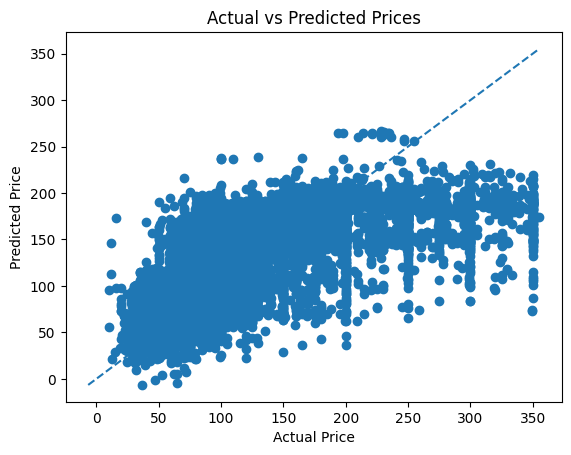

In [8]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")

a = min(y_test.min(), y_pred.min())
b = max(y_test.max(), y_pred.max())

plt.plot([a, b], [a, b], "--")
plt.show()

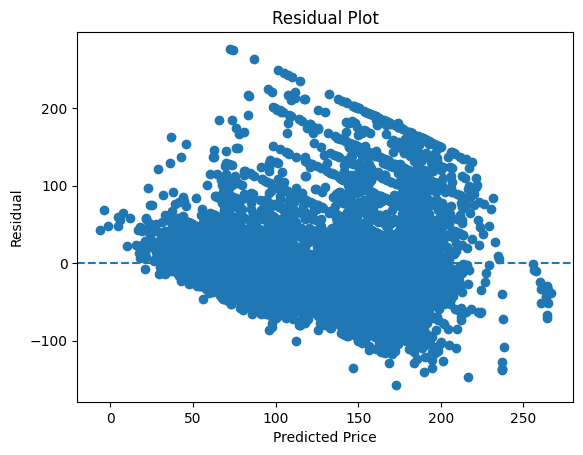

In [9]:
residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()

Group
(9.999, 66.0]     26.211232
(66.0, 100.0]     31.687319
(100.0, 160.0]    31.324502
(160.0, 355.0]    64.112438
Name: Error, dtype: float64


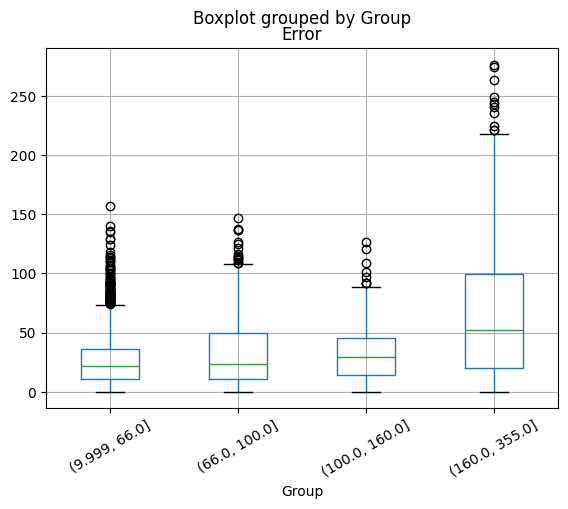

In [10]:
result = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

result["Error"] = abs(
    result["Actual"] - result["Predicted"]
)

result["Group"] = pd.qcut(
    result["Actual"], 4, duplicates="drop"
)

print(result.groupby("Group", observed=True)["Error"].mean())

result.boxplot(column="Error", by="Group")
plt.xticks(rotation=30)
plt.show()